### Prof. Alfio Ferrara

# La tokenizzazione

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente abbiamo trasformato i testi in vettori contando le parole, ma ci siamo fermati su una domanda: **come si divide davvero un testo in parole?** Oggi rispondiamo.

## Dividere il testo: la prima idea

Un testo per il computer è una sequenza di caratteri. Prima di poter contare qualcosa dobbiamo decidere quali sono le **unità** da contare. Chiamiamo queste unità **token** e l'operazione che le produce **tokenizzazione**.

Il metodo più semplice è tagliare il testo in corrispondenza degli spazi, con `split()`. Proviamo su alcune frasi scelte apposta.

In [1]:
frasi = [
    "Dell'Italia c'è l'Appennino, non l'Himalaya.",
    "Costa 1.500 euro (circa 12,5%) - dott. Rossi dixit: «vediamo!».",
    "Scrivimi a info@unimi.it o su https://www.unimi.it #clima",
    "Un po' d'acqua; l'all'erta; sull'altopiano; perché?",
]

for frase in frasi:
    print(frase)
    print(frase.split())
    print()

Dell'Italia c'è l'Appennino, non l'Himalaya.
["Dell'Italia", "c'è", "l'Appennino,", 'non', "l'Himalaya."]

Costa 1.500 euro (circa 12,5%) - dott. Rossi dixit: «vediamo!».
['Costa', '1.500', 'euro', '(circa', '12,5%)', '-', 'dott.', 'Rossi', 'dixit:', '«vediamo!».']

Scrivimi a info@unimi.it o su https://www.unimi.it #clima
['Scrivimi', 'a', 'info@unimi.it', 'o', 'su', 'https://www.unimi.it', '#clima']

Un po' d'acqua; l'all'erta; sull'altopiano; perché?
['Un', "po'", "d'acqua;", "l'all'erta;", "sull'altopiano;", 'perché?']



### Il risultato vi convince?

- Quali token contengono la punteggiatura? Per un programma che conta le parole, `"l'Appennino,"` e `"l'Appennino"` sono la stessa parola?
- Con l'apostrofo, `"dell'Italia"` è una parola sola o due? E in `"l'all'erta"`?
- Che cosa dovrebbe fare un buon tokenizzatore con `1.500`, con `12,5%`, con un indirizzo email?
- Le regole cambierebbero passando a un'altra lingua? Pensate all'inglese *don't*, al tedesco *Donaudampfschifffahrtsgesellschaft*, al cinese, che non usa spazi.

## NLTK

**NLTK** (*Natural Language Toolkit*) è una libreria storica per l'elaborazione del linguaggio naturale, nata in ambito didattico. Il suo tokenizzatore per le parole, `word_tokenize`, accetta il nome della lingua, che influenza il modo in cui vengono riconosciuti i confini di frase.

In [2]:
from nltk.tokenize import word_tokenize

for frase in frasi:
    print(frase)
    print(word_tokenize(frase, language='italian'))
    print()

Dell'Italia c'è l'Appennino, non l'Himalaya.
["Dell'Italia", 'c', "'", 'è', "l'Appennino", ',', 'non', "l'Himalaya", '.']

Costa 1.500 euro (circa 12,5%) - dott. Rossi dixit: «vediamo!».
['Costa', '1.500', 'euro', '(', 'circa', '12,5', '%', ')', '-', 'dott', '.', 'Rossi', 'dixit', ':', '«', 'vediamo', '!', '»', '.']

Scrivimi a info@unimi.it o su https://www.unimi.it #clima
['Scrivimi', 'a', 'info', '@', 'unimi.it', 'o', 'su', 'https', ':', '//www.unimi.it', '#', 'clima']

Un po' d'acqua; l'all'erta; sull'altopiano; perché?
['Un', 'po', "'", "d'acqua", ';', "l'all'erta", ';', "sull'altopiano", ';', 'perché', '?']



Confrontiamo i due metodi sulla prima frase, token per token.

In [3]:
import pandas as pd

def confronta(frase, **metodi):
    """Tabella con i token prodotti da ciascun metodo, in colonne."""
    liste = {nome: f(frase) for nome, f in metodi.items()}
    lunghezza = max(len(l) for l in liste.values())
    return pd.DataFrame({nome: l + [''] * (lunghezza - len(l)) for nome, l in liste.items()})

confronta(
    frasi[0],
    split=str.split,
    nltk=lambda t: word_tokenize(t, language='italian'),
)

,split,nltk
0,Dell'Italia,Dell'Italia
1,c'è,c
2,"l'Appennino,",'
3,non,è
4,l'Himalaya.,l'Appennino
5,,","
6,,non
7,,l'Himalaya
8,,.


### Cosa fa NLTK, e cosa no

- Dove ha separato la punteggiatura? Ha risolto il problema delle virgole e dei punti?
- Come ha trattato `c'è`? E `l'Appennino`? Sono scelte coerenti tra loro?
- Guardate l'indirizzo email e l'indirizzo web della terza frase. Il risultato ha ancora senso?
- Un tokenizzatore è un programma che applica delle **regole**. Chi decide quali regole sono giuste?

### Anche le frasi sono unità

A volte l'unità giusta non è la parola ma la **frase**. Dividere il testo in frasi sembra facile (basta tagliare ai punti) finché non si incontrano abbreviazioni e numeri decimali.

In [4]:
from nltk.tokenize import sent_tokenize

testo = "Il dott. Rossi vive a Roma. Dice: «Piove!» Ma non è vero. Costa 1.5 euro."

print('Taglio ai punti:')
for f in testo.split('.'):
    print('  ', repr(f.strip()))

print()
print('sent_tokenize:')
for f in sent_tokenize(testo, language='italian'):
    print('  ', repr(f))

Taglio ai punti:
   'Il dott'
   'Rossi vive a Roma'
   'Dice: «Piove!» Ma non è vero'
   'Costa 1'
   '5 euro'
   ''

sent_tokenize:
   'Il dott.'
   'Rossi vive a Roma.'
   'Dice: «Piove!» Ma non è vero.'
   'Costa 1.5 euro.'


### Dove sbagliano i due metodi?

- Cosa succede a «dott.» con il taglio ai punti? E con `sent_tokenize`?
- `sent_tokenize` non è magia: ha **imparato** dove tendono a cadere le fine frase da un corpus di testi italiani. Come potrebbe averlo imparato?
- Per una domanda come «quante frasi ha un romanzo?», quanto ci fidiamo del risultato?

## spaCy

**spaCy** è una libreria più recente, pensata per l'uso in produzione. Oltre al tokenizzatore offre una **pipeline** completa di analisi linguistica (la vedremo nella lezione sui livelli di analisi). Qui usiamo solo la prima parte, il tokenizzatore.

Il modello per l'italiano si carica per nome. Lo spazio dei nomi `nlp` è il nostro oggetto di lavoro.

In [5]:
import spacy

nlp = spacy.load('it_core_news_lg')
nlp.pipe_names

['tok2vec',
 'morphologizer',
 'tagger',
 'parser',
 'lemmatizer',
 'attribute_ruler',
 'ner']

Il risultato di `nlp(testo)` è un oggetto `Doc`: una sequenza di `Token`, ciascuno con la sua stringa e diverse proprietà già calcolate. Per ora ci interessa solo il testo dei token.

In [6]:
for frase in frasi:
    doc = nlp(frase)
    print(frase)
    print([t.text for t in doc])
    print()

Dell'Italia c'è l'Appennino, non l'Himalaya.
["Dell'", 'Italia', "c'", 'è', "l'", 'Appennino', ',', 'non', "l'", 'Himalaya', '.']

Costa 1.500 euro (circa 12,5%) - dott. Rossi dixit: «vediamo!».
['Costa', '1.500', 'euro', '(', 'circa', '12,5', '%', ')', '-', 'dott', '.', 'Rossi', 'dixit', ':', '«', 'vediamo', '!', '»', '.']

Scrivimi a info@unimi.it o su https://www.unimi.it #clima
['Scrivimi', 'a', 'info@unimi.it', 'o', 'su', 'https://www.unimi.it', '#', 'clima']

Un po' d'acqua; l'all'erta; sull'altopiano; perché?
['Un', "po'", "d'", 'acqua', ';', "l'", "all'", 'erta', ';', "sull'", 'altopiano', ';', 'perché', '?']



Ora mettiamo insieme i tre tokenizzatori sulla prima frase.

In [7]:
confronta(
    frasi[0],
    split=str.split,
    nltk=lambda t: word_tokenize(t, language='italian'),
    spacy=lambda t: [tok.text for tok in nlp(t)],
)

,split,nltk,spacy
0,Dell'Italia,Dell'Italia,Dell'
1,c'è,c,Italia
2,"l'Appennino,",',c'
3,non,è,è
4,l'Himalaya.,l'Appennino,l'
5,,",",Appennino
6,,non,","
7,,l'Himalaya,non
8,,.,l'
9,,,Himalaya


### Tre tokenizzatori, tre risposte

- Come tratta spaCy gli apostrofi? Confrontate `l'Appennino` nelle tre colonne.
- Quale scelta vi sembra più utile per contare le parole *Appennino*, *Italia*, *Himalaya* in un corpus? Perché?
- E quale scelta è più utile per capire che `c'` è il pezzo di *ci* (*ci è*)?
- Provate le altre tre frasi con `confronta`. Dove i tre metodi concordano? Dove no?

### Le regole di spaCy sono leggibili

spaCy usa un tokenizzatore **a regole**: prima taglia sugli spazi, poi guarda ogni pezzo e applica eccezioni, prefissi, suffissi, infissi. Possiamo chiedergli quale regola ha applicato a ogni pezzo.

In [8]:
frase = "Dell'Italia c'è l'Appennino, 1.500 euro."

pd.DataFrame(nlp.tokenizer.explain(frase), columns=['regola', 'token'])

,regola,token
0,TOKEN,Dell'
1,TOKEN,Italia
2,TOKEN,c'
3,TOKEN,è
4,TOKEN,l'
5,TOKEN,Appennino
6,SUFFIX,","
7,TOKEN,1.500
8,TOKEN,euro
9,SUFFIX,.


### Da dove vengono le regole?

- Che differenza c'è tra `TOKEN`, `SUFFIX` e le altre etichette? Cosa significa che una regola è un *suffisso*?
- Perché `1.500` non è stato spezzato in `1`, `.`, `500`?
- Se volessimo trattare gli hashtag come `#clima` come un unico token, quale tipo di regola dovremmo aggiungere o togliere?

### Token con proprietà

Un token spaCy non è soltanto una stringa. Ha attributi che dicono *che tipo* di token è, e che ci serviranno per filtrare: la punteggiatura, i numeri, le parole grammaticali molto frequenti (le *stop word*, che abbiamo incontrato alla fine del notebook precedente).

In [9]:
doc = nlp("A Giacarta piove molto: nel 2024 sono caduti 1.800 mm di pioggia.")

pd.DataFrame([
    {'token': t.text, 'lemma': t.lemma_, 'punteggiatura': t.is_punct, 'numero': t.like_num, 'stop word': t.is_stop}
    for t in doc
])

,token,lemma,punteggiatura,numero,stop word
0,A,a,False,False,True
1,Giacarta,Giacarta,False,False,False
2,piove,piovere,False,False,False
3,molto,molto,False,False,True
4,:,:,True,False,False
5,nel,in il,False,False,True
6,2024,2024,False,True,False
7,sono,essere,False,False,True
8,caduti,cadere,False,False,False
9,1.800,1.800,False,True,False


### Filtrare per tipo

- Quali token sono marcati come *stop word*? Sono le parole che nel notebook precedente rendevano simili testi di argomenti diversi?
- Se tenessimo solo i token che non sono punteggiatura, numeri o stop word, quali parole resterebbero? Bastano per capire di cosa parla la frase?
- Dove sta il rischio nel togliere le stop word? Pensate a *non*, o all'espressione *essere o non essere*.

In [10]:
[t.text for t in doc if not (t.is_punct or t.like_num or t.is_stop)]

['Giacarta', 'piove', 'caduti', 'mm', 'pioggia']

## Ricontiamo le parole

Ora che sappiamo perché la divisione conta, ricostruiamo il vocabolario dei 100 testi del dataset con il tokenizzatore di spaCy, che ha separato correttamente gli apostrofi, e lo confrontiamo con quello che otteniamo da `split()`.

In [11]:
import json
from collections import Counter

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

testi = [voce['testo'] for voce in dataset]

con_split = Counter(p.lower() for t in testi for p in t.split())
con_spacy = Counter(tok.text.lower() for t in testi for tok in nlp(t) if tok.is_alpha)

print('split: ', sum(con_split.values()), 'token,', len(con_split), 'forme diverse')
print('spacy: ', sum(con_spacy.values()), 'token,', len(con_spacy), 'forme diverse')

split:  2860 token, 742 forme diverse
spacy:  2860 token, 608 forme diverse


In [12]:
print('Le 12 forme più frequenti con split:')
print(con_split.most_common(12))
print()
print('Le 12 forme più frequenti con spaCy:')
print(con_spacy.most_common(12))

Le 12 forme più frequenti con split:
[('e', 235), ('sono', 90), ('le', 88), ('è', 85), ('il', 83), ('con', 81), ('estati', 53), ('piogge', 52), ('inverni', 52), ('a', 46), ('di', 44), ('la', 40)]

Le 12 forme più frequenti con spaCy:
[('e', 235), ('sono', 90), ('le', 88), ('è', 85), ('il', 83), ('con', 81), ('piogge', 55), ('estati', 54), ('inverni', 52), ('a', 46), ('di', 44), ('la', 40)]


### Token e forme

Chiamiamo **token** ogni occorrenza di una parola nel testo, e **tipi** (o *forme*) le parole distinte.

- Quanti token e quanti tipi ci sono nelle due versioni? Perché con `split()` i tipi sono di più?
- Confrontate le occorrenze di `piogge` nelle due liste. Perché `split()` ne conta meno? Cercate in `con_split` le altre forme in cui compare, per esempio con la punteggiatura attaccata.
- Quali sono le forme più frequenti? Hanno a che fare con il clima?

## Il vocabolario è un problema

Ogni **tipo** diventa una colonna della tabella dei conteggi. Quante colonne avremo? E quante volte compare ciascun tipo?

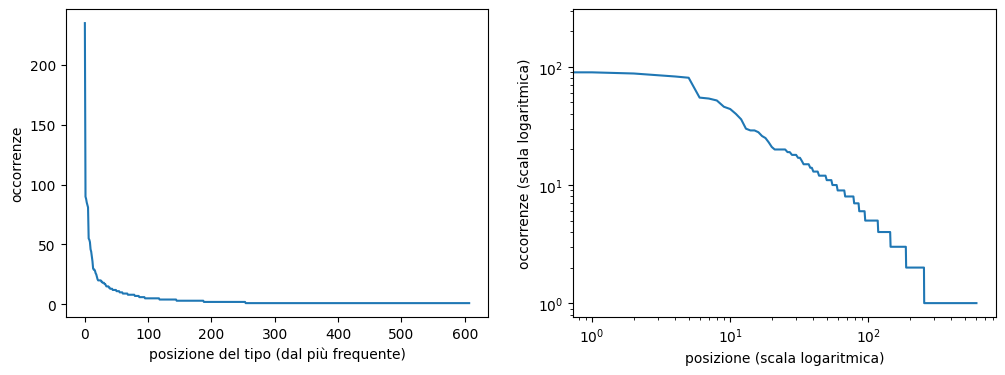

354 tipi su 608 compaiono una sola volta


In [13]:
import matplotlib.pyplot as plt

frequenze = sorted(con_spacy.values(), reverse=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(frequenze)
ax1.set_xlabel('posizione del tipo (dal più frequente)')
ax1.set_ylabel('occorrenze')
ax2.plot(frequenze)
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('posizione (scala logaritmica)')
ax2.set_ylabel('occorrenze (scala logaritmica)')
plt.show()

una_volta = sum(1 for f in con_spacy.values() if f == 1)
print(una_volta, 'tipi su', len(con_spacy), 'compaiono una sola volta')

### La coda lunga

- Che forma ha la curva a sinistra? Pochissimi tipi hanno frequenza alta, moltissimi hanno frequenza 1. Cosa vuol dire per la tabella dei conteggi?
- Quanti tipi compaiono una volta sola? Che informazione ci danno per confrontare *due testi*?
- Aggiungiamo altri 100 testi: il vocabolario cresce di poco o di molto? Provate a dirlo prima di sapere la risposta.

### Parole mai viste

Un vocabolario fatto di parole ha un limite strutturale: ciò che non è mai comparso non esiste. Costruiamo un vocabolario dai 100 testi e vediamo cosa succede con parole nuove.

In [14]:
vocabolario = set(con_spacy)

nuove = ['piogge', 'pioggerella', 'piovosissimo', 'ipertermico', 'nevicate', 'Giacarta', 'Yakutsk', 'clima😀']

for parola in nuove:
    print(f'{parola:15}', 'nel vocabolario' if parola.lower() in vocabolario else 'SCONOSCIUTA')

piogge          nel vocabolario
pioggerella     SCONOSCIUTA
piovosissimo    SCONOSCIUTA
ipertermico     SCONOSCIUTA
nevicate        nel vocabolario
Giacarta        nel vocabolario
Yakutsk         SCONOSCIUTA
clima😀          SCONOSCIUTA


### Cosa facciamo di una parola sconosciuta?

- Quali delle parole nuove sono sconosciute? Sono davvero parole sbagliate o inesistenti?
- *piovosissimo* non c'è, ma *piovoso*, *piogge* e *molto* sì. Una persona che non l'ha mai letta la capisce. Come?
- Un sistema di classificazione che incontra una parola sconosciuta la ignora. Cosa perdiamo?
- L'italiano, il tedesco, il turco formano parole nuove continuamente, attaccando pezzi. Un vocabolario fisso può reggere?

## Un'idea: sotto la parola

Abbiamo visto due estremi.

- **Caratteri.** Il vocabolario è minuscolo (poche decine di simboli) e nessuna parola è sconosciuta, ma ogni unità è priva di significato (L06).
- **Parole.** Ogni unità porta significato, ma il vocabolario è enorme e ci sono sempre parole sconosciute.

L'idea è cercare una via di mezzo: unità **più grandi dei caratteri ma più piccole delle parole**, come *piov*, *-osis*, *-simo*, *iper*, *-termico*. Pezzi che si riutilizzano in molte parole e che con poche migliaia di elementi permettono di scrivere (quasi) qualunque parola, anche mai vista. Si chiamano **sottoparole** (*subword*).

Cominciamo a vedere come si userebbe un vocabolario di sottoparole, prima di chiederci come costruirlo. Scriviamone uno a mano.

## Usare un vocabolario di sottoparole

Il metodo di **WordPiece**, usato da BERT, funziona così. Dato un vocabolario di pezzi:

1. si parte dall'inizio della parola e si cerca il pezzo **più lungo** del vocabolario che corrisponde all'inizio;
2. lo si stacca e si ripete dal punto in cui ci si è fermati;
3. i pezzi che *non* sono all'inizio della parola si marcano con il prefisso `##`, per distinguere `##simo` (parte di una parola) da `simo` (parola a sé);
4. se in qualche punto nessun pezzo corrisponde, la parola intera diventa `[UNK]` (sconosciuta).

In [15]:
vocabolario_a_mano = {'piov', '##os', '##issim', '##o', 'iper', '##termic', 'termic', 'piogge',
                      'molto', 'clima', 'p', '##i', '##o', '##v', '##s', '##m', '##e', '##r', '##t'}

def tokenizza_parola(parola, vocabolario):
    pezzi, inizio = [], 0
    while inizio < len(parola):
        fine = len(parola)
        while fine > inizio:
            pezzo = parola[inizio:fine] if inizio == 0 else '##' + parola[inizio:fine]
            if pezzo in vocabolario:
                break
            fine -= 1
        if fine == inizio:
            return ['[UNK]']
        pezzi.append(pezzo)
        inizio = fine
    return pezzi

for parola in ['piogge', 'piovosissimo', 'ipertermico', 'clima', 'xilofono']:
    print(f'{parola:15}', tokenizza_parola(parola, vocabolario_a_mano))

piogge          ['piogge']
piovosissimo    ['piov', '##os', '##issim', '##o']
ipertermico     ['iper', '##termic', '##o']
clima           ['clima']
xilofono        ['[UNK]']


### Come si comporta il vocabolario fatto a mano?

- Quali parole restano intere? Quali vengono spezzate? Dove avviene il taglio, e secondo quale criterio?
- Come mai *xilofono* diventa `[UNK]` nonostante i pezzi singoli come `##o` ci siano? Cosa manca?
- Togliete `##issim` dal vocabolario e riprovate con *piovosissimo*. Che cosa cambia nei pezzi?
- Aggiungete a mano un pezzo che faccia comparire *piovoso* in due parti sensate. Quanti pezzi ci vorrebbero per coprire tutti i comportamenti dell'italiano?

## Come si costruisce il vocabolario

Il vocabolario a mano funziona, ma scriverlo per tutte le lingue e tutti i testi è impensabile. WordPiece lo **impara dai dati**, con un procedimento che si può descrivere in poche righe:

1. si parte da un vocabolario di soli **caratteri** (con la distinzione tra inizio parola e continuazione, `##`);
2. si guarda ogni **coppia di pezzi adiacenti** nel corpus e si assegna un punteggio;
3. si **fonde** la coppia col punteggio migliore in un pezzo nuovo e lo si aggiunge al vocabolario;
4. si ripete finché il vocabolario ha la dimensione voluta.

Il punteggio è il cuore del metodo. Per una coppia $(a, b)$:

$$\text{punteggio}(a, b) = \frac{\text{freq}(ab)}{\text{freq}(a)\cdot\text{freq}(b)}$$

dove $\text{freq}(ab)$ è quante volte la coppia compare nel corpus, e $\text{freq}(a)$ e $\text{freq}(b)$ quante volte compaiono i due pezzi presi da soli. Una coppia frequente guadagna, ma se i due pezzi sono già molto frequenti anche separatamente il punteggio si abbassa: si fondono le coppie che **stanno insieme più di quanto ci si aspetterebbe per caso**.

(Se al posto del rapporto si usasse solo $\text{freq}(ab)$ si otterrebbe un altro algoritmo, *Byte-Pair Encoding*, usato da GPT.)

### Prima di guardare il codice

- Una coppia di lettere comunissime, come *e* e *r*, avrà un punteggio alto o basso? E una coppia come *q* e *u*, che quasi sempre compaiono insieme?
- Che cosa ci aspettiamo come primi pezzi? Sillabe? Prefissi? Parole intere?
- Se aumentiamo la dimensione del vocabolario, a un certo punto diventerà uguale al vocabolario delle parole. Perché?

In [16]:
def in_pezzi(parola):
    """Una parola come lista di caratteri: il primo senza prefisso, gli altri con ##."""
    return [parola[0]] + ['##' + c for c in parola[1:]]

in_pezzi('piogge')

['p', '##i', '##o', '##g', '##g', '##e']

In [17]:
def addestra(frequenze_parole, dimensione, minimo=1):
    """Impara un vocabolario WordPiece. Restituisce vocabolario e lista delle fusioni."""
    pezzi = {parola: in_pezzi(parola) for parola in frequenze_parole}
    vocabolario = {p for lista in pezzi.values() for p in lista}
    fusioni = []

    while len(vocabolario) < dimensione:
        freq_pezzo, freq_coppia = Counter(), Counter()
        for parola, freq in frequenze_parole.items():
            lista = pezzi[parola]
            for p in lista:
                freq_pezzo[p] += freq
            for a, b in zip(lista, lista[1:]):
                freq_coppia[(a, b)] += freq

        candidate = {c: n for c, n in freq_coppia.items() if n >= minimo}
        if not candidate:
            break
        a, b = max(candidate, key=lambda c: candidate[c] / (freq_pezzo[c[0]] * freq_pezzo[c[1]]))
        nuovo = a + b[2:]          # b perde il prefisso ## quando si attacca ad a

        for parola, lista in pezzi.items():
            i, risultato = 0, []
            while i < len(lista):
                if i < len(lista) - 1 and lista[i] == a and lista[i + 1] == b:
                    risultato.append(nuovo)
                    i += 2
                else:
                    risultato.append(lista[i])
                    i += 1
            pezzi[parola] = risultato

        vocabolario.add(nuovo)
        fusioni.append((a, b, nuovo))

    return vocabolario, fusioni

Il corpus di partenza è l'elenco dei tipi con le loro frequenze, che abbiamo già in `con_spacy`. Partiamo dai soli caratteri e chiediamo 250 pezzi in più. Per un corpus così piccolo ignoriamo le coppie che compaiono meno di 5 volte: con pochi dati una coppia vista una volta sola può avere un punteggio altissimo per puro caso.

In [18]:
caratteri_iniziali = {p for parola in con_spacy for p in in_pezzi(parola)}
print(len(caratteri_iniziali), 'pezzi di partenza (caratteri)')

vocabolario_wp, fusioni = addestra(con_spacy, dimensione=len(caratteri_iniziali) + 250, minimo=5)

print(len(vocabolario_wp), 'pezzi alla fine')
print()
print('Le prime 30 fusioni:')
for a, b, nuovo in fusioni[:30]:
    print(f'{a:>8} + {b:<8} -> {nuovo}')

58 pezzi di partenza (caratteri)
308 pezzi alla fine

Le prime 30 fusioni:
     ##f + ##f      -> ##ff
     ##z + ##z      -> ##zz
       q + ##u      -> qu
     ##q + ##u      -> ##qu
     ##b + ##b      -> ##bb
       u + ##m      -> um
     ##m + ##p      -> ##mp
     ##m + ##b      -> ##mb
       a + ##bb     -> abb
       o + ##c      -> oc
      oc + ##c      -> occ
     ##c + ##h      -> ##ch
     ##c + ##qu     -> ##cqu
       a + ##cqu    -> acqu
       o + ##g      -> og
       g + ##h      -> gh
       c + ##h      -> ch
     ##g + ##h      -> ##gh
     ##g + ##g      -> ##gg
     ##s + ##ch     -> ##sch
     ##c + ##ch     -> ##cch
     ##t + ##à      -> ##tà
      og + ##n      -> ogn
     ##b + ##u      -> ##bu
       f + ##r      -> fr
    ##mb + ##r      -> ##mbr
       s + ##p      -> sp
       u + ##n      -> un
       t + ##u      -> tu
      tu + ##t      -> tut


### Cosa ha imparato l'algoritmo?

- Guardate le prime fusioni: sono sillabe, prefissi, parti di parola? Avreste scelto gli stessi pezzi?
- Nessuno ha detto all'algoritmo cos'è una sillaba o un suffisso. Da cosa dipendono i pezzi che ha trovato?
- Con un altro corpus (testi di cucina, di legge, di poesia) i pezzi sarebbero gli stessi?
- Guardate le ultime fusioni: sono pezzi generali o parole intere?

In [19]:
print('Le ultime 20 fusioni:')
for a, b, nuovo in fusioni[-20:]:
    print(f'{a:>8} + {b:<8} -> {nuovo}')

Le ultime 20 fusioni:
       c + ##lim    -> clim
    clim + ##a      -> clima
    ##im + ##a      -> ##ima
     ##i + ##ssim   -> ##issim
     ##r + ##ima    -> ##rima
       p + ##rima   -> prima
   ##ima + ##n      -> ##iman
     ##t + ##iman   -> ##timan
     ##t + ##timan  -> ##ttiman
     ##e + ##ttiman -> ##ettiman
       s + ##ettiman -> settiman
settiman + ##e      -> settimane
     gel + ##i      -> geli
    geli + ##d      -> gelid
   gelid + ##i      -> gelidi
     gel + ##o      -> gelo
       c + ##o      -> co
      co + ##p      -> cop
      co + ##n      -> con
      co + ##s      -> cos


Applichiamo il vocabolario appreso alle parole che avevamo trovato sconosciute.

In [20]:
for parola in nuove[:-1]:
    print(f'{parola.lower():15}', tokenizza_parola(parola.lower(), vocabolario_wp))

piogge          ['piogge']
pioggerella     ['piogge', '##r', '##e', '##l', '##l', '##a']
piovosissimo    ['p', '##i', '##o', '##v', '##o', '##s', '##issim', '##o']
ipertermico     ['i', '##p', '##e', '##r', '##t', '##e', '##r', '##m', '##i', '##c', '##o']
nevicate        ['n', '##e', '##v', '##i', '##c', '##a', '##t', '##e']
giacarta        ['gi', '##a', '##c', '##a', '##r', '##t', '##a']
yakutsk         ['[UNK]']


### Le parole nuove non sono più sconosciute?

- *piovosissimo* ha ora dei pezzi. Sono pezzi sensati? Corrispondono a quello che avremmo scritto a mano?
- Quali parole sono rimaste intere? Che cosa hanno in comune?
- Perché *yakutsk* diventa `[UNK]`? Quale pezzo manca al vocabolario? Perché *ipertermico* si riduce quasi a caratteri singoli?
- Provate con vocabolari più grandi o più piccoli (cambiate `dimensione`). Cosa succede ai pezzi di *ipertermico* e *nevicate*?

## Un vocabolario vero

Il nostro vocabolario ha imparato da 100 brevi descrizioni. Un modello come BERT lo impara da miliardi di parole. Carichiamo il tokenizzatore italiano di BERT (`dbmdz/bert-base-italian-cased`), che usa proprio WordPiece, tramite la libreria `transformers`.

In [21]:
from transformers import AutoTokenizer

bert_it = AutoTokenizer.from_pretrained('dbmdz/bert-base-italian-cased')
print('Dimensione del vocabolario:', bert_it.vocab_size)

Dimensione del vocabolario: 31102


In [22]:
parole_test = ['piogge', 'piovosissimo', 'ipertermico', 'tokenizzazione', 'Giacarta', 'Jakutsk', 'clima😀']

for parola in parole_test:
    print(f'{parola:16}', bert_it.tokenize(parola))

piogge           ['piogge']
piovosissimo     ['pio', '##vos', '##is', '##simo']
ipertermico      ['iper', '##ter', '##mico']
tokenizzazione   ['to', '##ken', '##i', '##zzazione']
Giacarta         ['Gia', '##car', '##ta']
Jakutsk          ['Ja', '##ku', '##ts', '##k']
clima😀           ['[UNK]']


Su una frase intera, con gli identificativi numerici che il modello riceve davvero.

In [23]:
frase = "Dell'Italia c'è l'Appennino, non l'Himalaya."

pezzi = bert_it.tokenize(frase)
ids = bert_it.convert_tokens_to_ids(pezzi)

pd.DataFrame({'pezzo': pezzi, 'id': ids})

,pezzo,id
0,Dell,18034
1,',1553
2,Italia,1560
3,c,107
4,',1553
5,è,198
6,l,181
7,',1553
8,App,2124
9,##enni,26142


### Cosa vede davvero il modello

- Quali parole sono rimaste intere? Quali sono state spezzate? Corrisponde alle nostre aspettative?
- Gli apostrofi sono separati, come in NLTK. Perché un tokenizzatore pensato per i modelli potrebbe non preoccuparsi di `l'` come lo fa spaCy?
- Per il modello l'input è la colonna `id`: numeri interi. A che cosa ci fa pensare, alla luce di L01?
- Cosa succede alla faccina `😀`? Il vocabolario ha 31 102 posti. Può contenere tutti i simboli di Unicode?

Confrontiamo tre vocabolari, scelti per lingue diverse, sullo stesso testo: un tokenizzatore addestrato su italiano, uno multilingue e uno solo inglese.

In [24]:
modelli = {
    'italiano': 'dbmdz/bert-base-italian-cased',
    'multilingue': 'bert-base-multilingual-cased',
    'inglese': 'bert-base-uncased',
}

tokenizzatori = {nome: AutoTokenizer.from_pretrained(m) for nome, m in modelli.items()}

for nome, tk in tokenizzatori.items():
    print(f'{nome} ({tk.vocab_size} pezzi)')
    for parola in ['piovosissimo', 'ipertermico', 'tokenizzazione']:
        print(f'  {parola:16}', tk.tokenize(parola))

italiano (31102 pezzi)
  piovosissimo     ['pio', '##vos', '##is', '##simo']
  ipertermico      ['iper', '##ter', '##mico']
  tokenizzazione   ['to', '##ken', '##i', '##zzazione']
multilingue (119547 pezzi)
  piovosissimo     ['pi', '##ovo', '##sis', '##simo']
  ipertermico      ['i', '##pert', '##erm', '##ico']
  tokenizzazione   ['tok', '##eni', '##zzazione']
inglese (30522 pezzi)
  piovosissimo     ['pi', '##ovo', '##sis', '##si', '##mo']
  ipertermico      ['ip', '##ert', '##er', '##mic', '##o']
  tokenizzazione   ['token', '##iz', '##za', '##zione']


### Il vocabolario riflette i dati

- Perché lo stesso testo italiano viene spezzato in modo diverso dai tre tokenizzatori?
- Il tokenizzatore inglese riesce comunque a rappresentare parole italiane. A che prezzo?
- Quanti pezzi servono per codificare una frase italiana con ciascun tokenizzatore? Quanto costa questo, se un modello processa un numero limitato di token alla volta?
- Un vocabolario appreso su testi di una lingua o di un'epoca non è neutro. Quali testi *non* avrebbe visto un modello addestrato su italiano contemporaneo? Cosa succederebbe con un testo del Duecento?

In [25]:
frase = "A Giacarta le piogge sono abbondanti e i temporali pomeridiani arrivano quasi senza preavviso."

for nome, tk in tokenizzatori.items():
    print(f'{nome:12}', len(tk.tokenize(frase)), 'pezzi per', len(frase.split()), 'parole')

italiano     19 pezzi per 14 parole
multilingue  29 pezzi per 14 parole
inglese      34 pezzi per 14 parole


## Cosa abbiamo imparato

1. **Tokenizzare** significa decidere le unità con cui il testo viene misurato. La scelta non è ovvia: `split()`, NLTK e spaCy danno risultati diversi perché applicano **regole** diverse a punteggiatura, apostrofi, numeri, indirizzi.
2. NLTK e spaCy producono token che somigliano a **parole**. spaCy dà accesso anche a proprietà dei token (punteggiatura, numeri, stop word) e permette di leggere le regole applicate.
3. Un vocabolario di parole ha **coda lunga** (molti tipi rari) e non sa trattare le parole mai viste.
4. **Sottoparole**: un vocabolario di pezzi intermedi tra caratteri e parole copre anche parole nuove. **WordPiece** lo impara dai dati fondendo le coppie che stanno insieme più di quanto ci si aspetterebbe per caso.
5. Il vocabolario riflette i **dati** su cui è stato appreso. Il modello non vede il testo ma una sequenza di identificativi numerici.

La divisione in token ci dà le colonne della tabella dei conteggi. Non abbiamo ancora risolto il problema di come **pesare** le colonne perché le parole grammaticali non dominino il confronto: sarà il tema del prossimo notebook.